<h2> Bioinformatyka2 - kurs mały. Ćwiczenie1. Bioinformatyka sekwencji nukleotydowych i białkowych

2026/2027, Adrian Kania

W poniższym ćwiczeniu poznamy wybrane metody związane z analizą sekwencji oraz biologicznymi bazami danych. Część zadań będzie zrealizowana przy pomocy języka Python. 

Zagadnienia poruszane podczas ćwiczenia:
- Dopasowanie sekwencji
- Entropia i logo sekwencji
- Wyszukiwanie motywu w grupie sekwencji, algorytm MEME
- Metody bez dopasowania (ang. free-alignment) do porównania sekwencji; CGR oraz metoda oparta o k-mery
- Wybrane bazdy danych z NCBI, UniProt i Prosite
- Elementy języka Python do analiz bioinformatycznych

<h3> Dopasowanie sekwencji, badanie konserwatywności

`Zadanie1`<h4> Będziemy analizować 16 sekwencji proteaz bakteryjnych. Centrum katalityczne tych proteaz obejmuje 3 reszty aminokwasowe: serynę (S), histydynę (H) i kwas asparaginowy (D).

a) Wykonaj dopasowanie tych sekwencji (https://www.ebi.ac.uk/jdispatcher/msa/clustalo)

b) Uzyskane dopasowanie wykorzystaj do wygenerowania logo sekwencji. Wklej tam otrzymane dopasowanie. (http://weblogo.threeplusone.com/create.cgi)
    
c) W bazie UniProt (https://www.uniprot.org/) wyszukaj sekwencję Q9AER6 (po ID) i odszukaj miejsca występowania trzech reszt z centrum katalitycznego. 
    
d) Na podstawie informacji z c) zlokalizuj te reszty w dopasowaniu oraz/lub logo. Podaj ich pozycje w dopasowaniu. Czy te pozycje są konserwatywne?

e) Na podstawie dopasowania sekwencji i/lub wygenerowanego logo, podaj prawdopodobne miejsca występowania tych reszt w sekwencji P08594. Następniem porównaj te wyniki z informacjami w bazie UniProt. Czy jest tutaj zgodność?
    
Uwaga: do samego sprawozdania oczywiście proszę nie załączać samego dopasowania czy logo, służą one tyko do realizacji pozostałych punktów; ewenutalnie można załączyć fragmenty (np. związane z analizowanymi resztami).
    

<h3> MEME

W analizie sekwencji często chcemy znaleźć charakterystyczny motyw, którego dokładna postać nie jest znana na początku. W takich przypadkach można wykorzystać algorytm MEME (Multiple EM for Motif Elicitation), który wyszukuje powtarzające się wzorce w zbiorze sekwencji DNA, RNA lub białek. Algorytm wykorzystuje metody statystyczne, aby określić najbardziej prawdopodobne motywy występujące w analizowanych sekwencjach.

praca mgr: Maja Motyczyńska, Rozpoznawanie motywów funkcyjnych w sekwencjach DNA i białek za pomocą algorytmu MEME i propozycja jego rozszerzeń, 2026 (https://www.ap.uj.edu.pl/diplomas/194315/)

`Zadanie2`<h4> Rozważamy rodzinę białek HSP70 (białka szoku cieplnego, pełniące rolę opiekuńczą względem innych białek, plik: hsp70.fasta). Wiadomo, że białka te zawierają konserwowany motyw w domenie odpowiedzialnej za wiązanie i hydrolizę ATP. Celem będzie rozpoznanie tego motywu - jaki on jest i gdzie występuje.

a) Wyszukaj konserwowany motyw w podanych sekwencjach za pomocą algorytmu MEME (https://meme-suite.org/meme/tools/meme). Wybierz motyw o najmniejszej wartości E-value i zamieść jego logo w sprawozdaniu. Jaka jest szerokość motywu? Sprawdź, czy wykryty motyw występuje we wszystkich analizowanych sekwencjach.

b) Wyszukaj w bazie PROSITE (https://prosite.expasy.org/) rekord PS00297. Wypisz i opisz słownie motyw charakterystyczny dla rodziny HSP70.
    
c) Sprawdź czy motyw znaleziony przez MEME pokrywa się z motywem z PROSITE (przynajmniej w części).

d) Ponownie wyszukaj motywy w analizowanych sekwencjach za pomocą MEME, tym razem ograniczając długość motywu do długości motywu znalezionego w PROSITE (wejdź na stronę analogicznie jak w a), zmieniając ustawienia szerokości motywu w Advanced Options). Wybierz motyw o najmniejszej wartości E-value i zamieść jego logo w sprawozdaniu. Czy tym razem wykryty motyw odpowiada motywowi z PROSITE? Czy występuje we wszystkich analizowanych sekwencjach?

e) Z czego może wynikać rozbieżność w detekcji motywu pomiędzy podejściem zastosowanym w punkcie a) i c)?


Przypomnienie:

<small><i>PROSITE = baza charakterystycznych motywów i profili białkowych, używanych do identyfikacji rodzin, domen i miejsc funkcjonalnych. </i></small>

<small><i>E-value (expected value) = określa oczekiwaną liczbę motywów o podobnym lub lepszym wyniku, które mogłyby pojawić się przypadkowo w analizowanych sekwencjach, przy czym im niższe E-value, tym większa istotność statystyczna motywu. </i></small>

#### PROSITE – najważniejsze symbole

| Symbol | Znaczenie |
|:---:|:---|
| `x` | Dowolny aminokwas |
| `[AG]` | Alanina lub glicyna |
| `{P}` | Dowolny aminokwas oprócz proliny |
| `x(3)` | Dokładnie 3 dowolne aminokwasy |
| `x(2,4)` | Od 2 do 4 dowolnych aminokwasów |
| `-` | Separator pozycji |

**Przykład:** `A-x-[ST]-{P}-x(2)-G` oznacza: alanina → dowolny aminokwas → seryna lub treonina → dowolny oprócz proliny → 2 dowolne aminokwasy → glicyna.

<h3> Analiza składu sekwencji

* Poniższe zadania będą realizowane w języku Python. Realizacja zadań będzie polegała na uruchomieniu kodu z odpowiednimi argumentami.

Z Python możesz korzystać w pracowni komputerowej jak i online: https://jupyter.org/try.

Na początku wklej poniższe 3 linijki do importu bibliotek 

In [10]:
import numpy as np #biblioteka do operacji na wektorach, macierzach, funkcje matematyczne itd..
import matplotlib.pyplot as plt #biblioteka do rysowania
import random as r #modul do generowania liczb losowych itp

<h3> Badanie składu i szukanie globalnych wzorców w sekwencjach biologicznych

- Generowanie losowej sekwencji 

a) Uwzględniając jedynie częstości nukleotydów

In [4]:
#Model1. Pozycje są niezależne
def random_seq(length, dist):
    '''Funkcja zwraca losową sekwencje o zadanej dlugosci i zadanej czestosci liter alfabetu'''
    distT = []
    h = 0
    for (k, v) in dist.items():
        h += v
        distT.append((k,h))
    s = ''
    for x in range(length):
        ran = r.random()
        for k,v in distT:
            if ran <= v:
                s+=k
                break
    return s


##############przyklad
dist = {'A':0, 'C':1/3,'G':1/3,'T':1/3} #A nie występuje, pozostałe nukleotydy z tą samą częstością
seq = random_seq(10, dist) #podajemy długość sekwencji, tutaj 10
##############
print(seq)

CTGGTCTCCC


b) Uwzględniając poprzedni nukleotyd przy generowaniu następnego

In [6]:
#Model2. Bieżący nukleotyd jest zależny od wcześniejszego (model Markowa rzędu 1):
def random_seq2(length, nuc, firstN, trans):
    '''Funkcja zwraca losowa sekwencje o zadanej dlugosci i zadanej macierzy przejsc'''
    s_losowa = ''
    for i in range(length):
        if i>0:
            s_losowa+=np.random.choice(nuc, 1, p=trans[s_losowa[-1]])[0]
        else:
            s_losowa+=np.random.choice(nuc, 1, p=firstN)[0]
    return s_losowa

nuc = ["A","C","G","T"]
trans = {} #macierz przejsc (mozemy zablokowac lub wzmocnić pewne przejścia, w przykladzie ponizej nie będzie sekwencji CA)


####################przyklad, brak dinukleotydu CA
#              "A",  "C",  "G",  "T"
trans['A'] = [0.25, 0.25, 0.25, 0.25]
trans['C'] = [0,    1/3,   1/3, 1/3]
trans['G'] = [0.25, 0.25, 0.25, 0.25]
trans['T'] = [0.25, 0.25, 0.25, 0.25]

firstN = [0.25, 0.25, 0.25, 0.25] #pierwszy nukleotyd będzie zupelnie losowy
seq = random_seq2(100, nuc, firstN, trans)  #podajemy dlugosc sekwencji, tutaj 100
#####################
print(seq)

GAAGTAGAGATGTTCGTGGGATTAGCTAAGAAAGAGACCTGTCCCTGCTAACTGACCTCTGTGGAGCCCTGACGTACTTTCTAAGGGGCGGTGCTATACC


 - Proste statystyki dla sekwencji

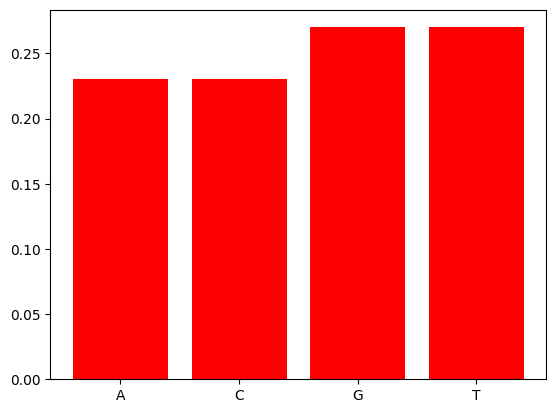

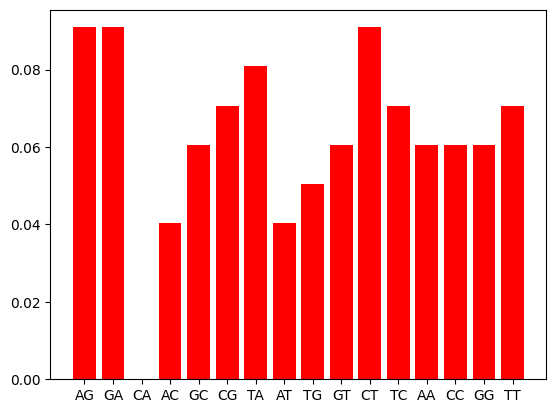

In [7]:
#Wyznaczanie częstosci nukleotydów i dinukleotydów dla zadanej sekwencji 
################################przyklad
seq = 'TGACCCCGGTTAAGAGCTAAGATCGCTTTAGGCGTTGGCGAAGTATCCTCTACGTCCTTCGGGAGAAAAGCTGTAGAGGTATCGCTTACTGATTGACTCC'
################################


letters = {'A':0, 'C':0, 'G':0, 'T':0}
diplets = {'AG':0, 'GA':0, 'CA':0, 'AC':0, 'GC':0, 'CG':0, 'TA':0,'AT':0,'TG':0, 'GT':0,'CT':0,'TC':0, 'AA':0, 'CC':0, 'GG':0, 'TT':0}

n = len(seq)-1
for i in range(n):
    letters[seq[i]]+=1
    diplets[seq[i:(i+2)]]+=1
letters[seq[n]]+=1


sumL = sum(letters.values())
norL = {k:v/sumL for k,v in letters.items()}
sumD = sum(diplets.values())
norD = {k:v/sumD for k,v in diplets.items()}

#wizuzalizacja dla nukleotydow
height_norL = norL.values()
bars = norL.keys()
y_pos = np.arange(len(bars))
plt.bar(y_pos, height_norL,color="red")
plt.xticks(y_pos, bars)
plt.show()

#wizuzalizacja dla dinukleotydow
height_norD = norD.values()
bars = norD.keys()
y_pos = np.arange(len(bars))
plt.bar(y_pos, height_norD,color="red")
plt.xticks(y_pos, bars)
plt.show()

- Reprezentacja gry chaosu (CGR)

CGR to metoda graficznego przedstawiania sekwencji DNA, w której każdy nukleotyd odpowiada punktowi na wykresie, co pozwala wizualizować i analizować wzorce oraz powtarzalność w sekwencji.

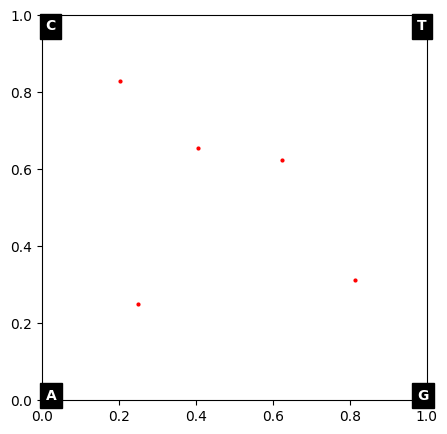

In [8]:
################przykład
seq = "ATGCC"
#######################

def CGR(seq):
    '''Funkcja wyznacza tzw. reprezentację gry chaosu dla danej sekwencji'''
    d = np.array([[0.5,0.5]])
    nt= ["A","C","G","T"]
    coordinates = np.array([[0,0],[0,1],[1,0],[1,1]])
    sequence = []
    for i in range(len(seq)):
        x=0.5*(d[len(d)-1]+coordinates[nt.index(seq[i])])
        sequence.append((x[0],x[1]))
        d = np.vstack((d, x))
    return np.array(sequence)

#przykladowe wywolanie tej funkcji i wizualizacja
p1 = CGR(seq) #wykorzystuje funkcje CGR, trzeba ją tez załączyc do kodu

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111)
plt.scatter(p1[:,0],p1[:,1],c = "red", s = 4, label = "CGR")
#plt.scatter([0.5],[0.5])
ax.text(0.01, 0.03, 'A', transform=ax.transAxes, fontweight='bold', va='top', ha='left',backgroundcolor='k', color='white')
ax.text(0.01, 0.99, 'C', transform=ax.transAxes, fontweight='bold', va='top', ha='left',backgroundcolor='k', color='white')
ax.text(0.975, 0.03, 'G', transform=ax.transAxes, fontweight='bold', va='top', ha='left',backgroundcolor='k', color='white')
ax.text(0.975, 0.99, 'T', transform=ax.transAxes, fontweight='bold', va='top', ha='left',backgroundcolor='k', color='white')

plt.xlim(0,1)
plt.ylim(0,1)
plt.gca().set_aspect('equal', adjustable='box')
#plt.savefig("obrazek.png", dpi=300) #Jak chcemy zapisac do pliku to odkomentowac (skasować # na początku)
plt.show()

`Zadanie3`<h4> Wygeneruj sekwencję losową o długości 10k, w której nie ma A (model1). Następnie narysuj wykresy częstości dla nukleotydów i dinukleotydów oraz zaprezentuj sekwencję graficznie (CGR). Załącz wykresy do sprawozdania.

`Zadanie4`<h4> Wygeneruj sekwencję losową o długości 10k, w której nie ma podsekwencji AG (model2). Następnie narysuj wykresy częstości dla nukleotydów i dinukleotydów oraz zaprezentuj sekwencję graficznie (CGR). Załącz wykresy do sprawozdania.

`Zadanie5`<h4> Wygeneruj sekwencję losową o długości 10k, w której nie ma podsekwencji AT (model2). Następnie narysuj wykresy częstości dla nukleotydów i dinukleotydów oraz zaprezentuj sekwencję graficznie (CGR). Załącz wykresy do sprawozdania.

`Zadanie6`<h4> Wykonanaj analogicznie obliczenia dla genomu mitochondrialnego ryby (https://www.ncbi.nlm.nih.gov/nuccore/NC_009057.1/); sekwecja ta znajduje się poniżej. Załącz wykresy do sprawozdania. Dodatkowo, skomentuj pokrótce otrzymane wykresy. Z czego może wynikać taki skład?

In [8]:
#NCBI ID: NC_009057.1

seq = "GCTAGCGTAGCTTAACTAAAGCATAACACTGAAGATGTTAAGACGGACCCTAGAAAGGCCCCGTAAGCACAAAGGCTTGGTCCTGACTTTACTGTCAGCTTTGGCTAAACTTACACATGCAAGTCTCCGCCCCCCTGTGAGAATGCCCACAGTTTTCTGCCCGAAAACAAGGAGCTGGTATCAGGCACAACCCTGCAGCCCATGACACCTTGCTTAGCCACACCCTCAAGGGAACTCAGCAGTGATAGACATTAAGCCATGAGTGAAAACTTGACTTAGTTAAAGCCAAGAGAGCCGGTAAAACTCGTGCCAGCCACCGCGGTTATACGAGAGGCTCAAGTTGACGGACATCGGCGTAAAGAGTGGTTAGGAAGTCTTTCAAACTAAAGCCGAACGCCCTCAGAACTGTTATACGTACCCGAGGGTAAGAAGCCCCCCTACGAAAGTGGCTTTATATCTCCGACCCCACGAAAGCTGCGAAACAAACTGGGATTAGATACCCCACTATGCCCAGCCCTAAACTTTGATAGCCCACTACACCCGCTATCCGCCCGGGTACTACGAGCACTAGCTTAAAACCCAAAGGACTTGGCGGTGCTTTAGATCCACCTAGAGGAGCCTGTTCTAGAACCGATAACCCCCGTTAAACCTCACCCTCTCTTGATCTTCCCGCCTATATACCGCCGTCGTCAGCTTACCCTATGAAGGAGCCACAGTAAGCAGAACTAGTACAACTCAAAACGCCAGGTCGAGGTGTAGCATATGAGAGGGGAAGAAATGGGCTACATTCCCTACCACAGGGAATACGAACAATGTAATGAAATATACATTAGAAGGAGGATTTAGCAGTAAGCAGAAAATAGAGCGTTCCGCTGAAACCGGCCCTGAAGCGCGCACACACCGCCCGTCACTCTCCCCAAACCAACTAACATCCTATAAATAATACATATTATCGGTAAAGGGGAGGCAAGTCGTAACATGGTAAGTGTACCGGAAGGTGCGCTTGGAAAAATCAGAGTGTAGCTAAGCCAGAAAAGCATCTCCCTTACACTGAGAAGTCACCCGTGCAAATCGAGTCACCCTGACGCCCAATAGCTAGCTCACCCATCAATCCCAAATCCACCCTATCTATACCCCCAAACACACCACCACCCAACAAACAAACCATTTTTCCACCTAAGTACAGGCGACGAAAAAGGACCTAGAAGCAACAGAGAAAGTACCGCAAGGGAAAGCTGAAAGAGAAGTGAAACAACCCAGTAAAGCACCAAAAAGCAGAGCTCGCCCCTCGTACCTTTTGCATCATGATTTAGCCAGAAAACCTTAAGCAAAAAGCATTATAGTTTAATACCCCGAAACTAGGCGAGCTACTCCAAGACAGTCTAATTTATAGGACCACCCCGTCTCTGTGGCAAAAGAGTGGGAAGAACTTTGAGTAGAGGTGATAGACCTACCGAGCCTAGTTATAGCTGGTTGCCTGAGAACTGAATAGAAGTTCAGCCCTTTAAATTCTTCATTCCCACTGGCCCAAGGCCTCCATACCGAACAAAAGAAGTTAAAGGAGTTAGTCAAAGGGGGTTCAGCCCCTTTGAAACAAGATACAACTTTCCAAGGAGGGTAAAGATCACAACAAACCTAAAGGTCTAGTGTCCTAGTGGGCCTAAAAGCAGCCACCTACTTAGAAAGCGTTAAAGCTCGAACACTACACACCAACCTTTTAATAAGGACAACACAATCTCACCCCCCTAAGCCTACCAGGCCATTCCATAAAAATTATGGAAGCGTTTATGCTAATATGAGTAATAAGAGAAGCCCCCTTCTCTCCCCGCACAAGTGTAATTCGGAACGAACCATTCACCGACCATTAACGGCCCCAAAACAAAGAGGGAACTAGACAAAAAATAAACAACTAGAAAATCACCTAACCTCCCACCGTTAACCCCACACTGGTGTGCCAATTGGGAAAGACCAAAAGAAAAAGAAGGAACTCGGCAAACACAAGCCTCGCCTGTTTACCAAAAACATCGCCTCTTGTACCCCTAAACATAAGAGGTCCCGCCTGCCCTGTGACTATAAGTTTAACGGCCGCGGTATTTTGACCGTGCAAAGGTAGCGCAATCACTTGTCTTTTAAATGAAGACCTGTATGAATGGCATAACGAGGGCTTAACTGTCTCCTTTTTCCAGTCAATGAAATTGATCTCCCCGTGCAGAAGCGGGGATACAAACATAAGACGAGAAGACCCTATGGAGCTTTAGACACCAGAACAGACCATGTTAAGCACCCCTGAAATAAAGGATAAAACTGATTGGCCCCTGTTCTAATGTCTTTGGTTGGGGCGACCGCGGGGAAACAAAAAACCCCCATGTGGACCGGGAGCACACTACTCCTACAACCCAGAGTTACAACTCCAAGCAACAGAATTTCTGACCAATAAGATCCGGCACATAGCCGATCAACGGACCGAGTTACCCTAGGGATAACAGCGCAATCCTCTTTTAGAGCCCATATCGACAAGAGGGTTTACGACCTCGATGTTGGATCAGGACATCCTAATGGTGCAGCCGCTATTAAGGGTTCGTTTGTTCAACGATTAAAGTCCTACGTGATCTGAGTTCAGACCGGAGTAATCCAGGTCAGTTTCTATCTATGCCACGATCTTTTCTAGTACGAAAGGACCGAAAAGAAGGGGCCCCTGTTCTCGACACGCCCCACCCTTACCTATTGAAACCAACTAAAATAGGTAAAAGGGCGTACCCCCTAGCCCAAGAAAATGGCTTGTTAAAGTGGCAGAGCCCGGACATTGCAAAAGACCTAAGCCCTTTCCACGGAGGTTCAAGTCCTCCCTTTAACTATGCTCTCAACACTAATTTCATCCATCCTCAACCCCCTAATCCTAATTGTGTTCGTCCTACTAGCCGTCGCACTCCTCACACTTGTCGAACGAAAAGTTCTTGGCTATATGCAACTACGAAAAGGCCCAAACGTTGTAGGCCCTTACGGCCTCCTCCAACCAATTGCAGACGGACTAAAACTTTTTATAAAAGAGCCCGTTCGGCCTTCTACCTCCTCCCCCATCCTCTTCCTCTTTACCCCCATGCTAGCCCTCACCCTAGCACTTACCCTTTGAACTCCAATACCCCTTCCCTTTCCAATAGCAGACCTCAATCTTGGTATCCTTTTTATTCTTGCTCTCTCCAGCTTAGCAGTCTATTCTATCCTCGGCTCGGGATGAGCCTCCAATTCAAAATACGCCTTAATTGGAGCTCTTCGAGCTGTCGCACAGACTATTTCCTACGAAGTCAGCCTAGGACTAATTCTTCTTAATGCCATCATCTTTACTGGAGGTTTTACCCTACAGACCTTTAGCATTGCTCAAGAAAGTGTCTGACTAATCCTTCCCGCCTGACCTTTAGCCGCTATATGATACATTTCCACACTTGCAGAAACTAACCGAGCTCCCTTCGACCTTACAGAAGGCGAATCCGAACTCGTCTCCGGCTTTAATGTAGAATATGCAGGAGGCCCTTTTGCCCTCTTTTTCCTCGCCGAATACGCCAACATTCTCCTAATAAACACACTCTCTGCAACACTATTTTTAGGTGCCTCCATTCTACACACAACCCCAGAAATTACAACAACAAACCTTATGATTAAAGCAACCCTTCTCTCTGTTCTTTTCCTATGAGTTCGAGCTTCCTACCCACGATTTCGTTATGACCAGCTTATGCACCTAATCTGAAAAAACTTCCTCCCATTGACCCTCGCCCTCGTAATTTGACACCTTTCCCTCCCAATCGCACTAACAGGCCTACCCCCACAACTATAGCCTGGAGTTGTGCCTGAAATAAAGGGCCACTTTGATAGAGTGAATCATGAGGGTTAAAGTCCCTCCAACTCCTTAGAAAGAAGGGGCTCGAACCCTACCTGAAGAGATCAAAACTCTTAGTGCTTCCACTACACCACTTCCTAGTAAAGTCAGCTAAATAAGCTTTTGGGCCCATACCCCAAACATGTTGGTTAAACTCCTTCCTTTACTAATGAATCCTTACATCTTAGCCATCCTCCTCTTTGGCTTAGGCCTTGGCACCACAATTACATTTGCTAGCTCCCACTGACTTCTCGCCTGAATAGGCCTTGAAATAAATACGCTAGCCATTATTCCCCTAATAGCTCAACACCACCACCCCCGAGCTGTCGAAGCTACAACCAAATATTTTTTAACCCAAGCTGCTGCAGCAGCTACCCTTCTATTCGCAAGCATCACTAACGCCTGACTAACAGGCCAATGAGAAATTCAACAAATCACGCATCCCCTCCCAACCACCATAATCACCCTAGCCCTAGCCCTCAAAATCGGCTTAGCACCTCTTCATGCTTGACTCCCCGAAGTTCTACAAGGACTAGACCTTACTACAGGCCTAATTCTTTCAACCTGGCAAAAACTTGCCCCCTTCGCCCTAATTCTTCAAATCCAACCTTCAAACTCAACCACCCTCATTATTTTAGGCCTTGCATCCACCCTCATTGGAGGCTGAGGCGGGCTAAATCAGACACAGCTCCGTAAAATTCTCGCATACTCATCAATCGCCCATCTAGGCTGAATAATTCTTGTTTTACAGTTTTCCCCTTCCATCACACTTCTCACCCTCCTAACGTACCTTATCATAACATCCTCAACATTCCTCGTATTCAAGCTCAACAAATCCACAAATATTAACACTCTTGCCACATCCTGAGCGAAAGCCCCCGCCCTCACAGCTCTTACCCCCCTCATTCTCCTTTCATTAGGAGGCCTCCCCCCTCTCACAGGCTTTATACCAAAATGACTAATTCTTCAAGAACTAACCAAACAAGGCCTTGCTCCTACCGCAACCCTGGCAGCCCTTTCAGCCCTCCTTAGCCTCTATTTTTACCTCCGCCTCTCCTACGCAATAACCCTCACTATTTCCCCTAACAGCCTCCTAGGCACCACCCCCTGACGTTTACCTTCCACCCAACTAACTTACCCCCTCGCCACTTCAACTGCAATGACAATTTGTCTCCTACCACTCACCCCCGCCATCTCAGCCTTACTAACCCCTTAAGGGACTTAGGATAGTACCCAGACCAAGGGCCTTCAAAGCCCTAAGCGGGAGTGAAAATCTCCCAGTCCCTGTTAAGACTTGCGGGATACTAACCCACATCTTCTGCATGCAAAACAGACACTTTAATTAAGCTAAAGCCTTACTAGACAGGAAGGCCTCGATCCTACAAACTCTTAGTTAACAGCTAAGCGCTTAAACCAACAAGCATCTGTCTAGCCTTTCCCCGCCCGCCTCAAAAAGGGCGGGGAAAGCCCCGGCAGGGGCTAACCTGCTACTTCAGATTTGCAATCTGACATGTATAACACCTCGAGGCTTGGTAAGAAGAGGACTTGAACCTCTGTACATGGGGCTACAATCCACCGCTTGACGCTCAGCCATCTTACCTGTGGCAATCACACGTTGATTCTTCTCAACTAATCACAAAGACATCGGCACCCTCTATCTAGTATTTGGTGCTTGAGCCGGAATAGTAGGAACTGCACTAAGCCTCCTAATTCGGGCAGAACTAAGCCAGCCCGGCTCTCTTCTCGGAGACGACCAAATCTATAATGTAATTGTTACAGCACATGCTTTCGTAATAATTTTCTTTATAGTAATACCAATTATGATTGGAGGCTTTGGAAACTGACTAGTACCCCTCATGATTGGTGCACCAGACATGGCCTTCCCTCGAATAAATAACATGAGCTTTTGACTTCTCCCCCCCTCATTTCTTCTTCTTCTCGCCTCATCTGGAGTCGAAGCAGGTGCCGGCACAGGATGGACTGTTTATCCCCCGCTCGCAGGCAATCTTGCCCACGCTGGACCTTCTGTTGACTTAACCATCTTCTCCCTCCACTTGGCCGGAGTGTCATCTATTTTAGGTGCAATTAATTTTATCACAACCATTATTAACATGAAACCCCCTGCCATCTCCCAATATCAAACACCCCTATTTGTGTGATCCGTCCTAATTACCGCAGTACTACTCCTTCTATCCCTGCCCGTTCTTGCCGCCGGCATCACAATACTTCTAACAGACCGAAACCTAAACACAACCTTCTTTGACCCTGCCGGAGGAGGAGACCCCATCCTATACCAACACTTATTCTGATTCTTTGGCCACCCTGAAGTTTATATTCTTATTCTCCCCGGCTTTGGAATAATTTCCCACATTGTTGCCTACTATGCAGGCAAAAAAGAACCTTTCGGATACATGGGAATGGTTTGAGCCATGATGGCTATCGGCCTCCTGGGGTTTATTGTTTGAGCCCACCACATGTTTACCGTAGGAATGGACGTAGATACACGGGCTTACTTTACTTCCGCCACAATAATTATTGCCATCCCAACCGGAGTAAAAGTCTTCAGCTGACTAGCCACTCTGCACGGCGGGGCCATTAAATGAGAAACCCCTCTCTTATGGGCACTAGGCTTCATTTTCCTATTTACAGTTGGGGGACTAACCGGAATTGTTCTAGCCAATTCTTCTCTAGACATTATGCTTCACGACACATATTATGTCGTCGCCCATTTCCACTATGTCCTCTCAATAGGAGCCGTTTTCGCCATCGTTGCCGGCTTCGTCCACTGATTCCCCCTATTTTCAGGATATACGCTTCACGACACTTGAACTAAAATCCACTTCGGAGTAATATTTGTTGGAGTCAACCTTACTTTCTTCCCACAACACTTCCTAGGCCTGGCAGGAATGCCTCGACGATACTCCGACTACCCCGACGCCTACACCCTTTGAAACACAATCTCTTCTATTGGCTCAATAATTTCAATAGTTGCAGTGATTATGTTTTTATTTATTATCTGAGAAGCATTCGCCGCTAAACGAGAAGTCCTATCAGTAGAACTTACAGCAACAAACGTAGAATGACTTCACGGCTGCCCTCCCCCTTATCACACATTTGAAGAACCTGCCTTCGTCCAAGTTCAACAAGCCTGACTAGACTACGGAAAATCCACTACCACCCCCTCAAAATCCCACTAACGAGAAAGGGAGGAATTGAACCCCCATAAACTGGTTTCAAGCCAGCCACATAACCACTCTGTCACTTTCTTCATAAGACACTAGTAAAGTTGATCATTACATTGCCTTGTCAAGGCAAAATTGCGGGTTTGAACCCCGCGTGTCTTACAACAATGGCACATCCCTCCCAACTAGGATTCCAAGATGCAGCTTCACCTGTAATAGAAGAACTTCTTCACTTCCACGACCACGCCCTAATAATCGTCTTCCTAATCAGCACCCTCGTGCTTTACATTATTGTGGCCATAGTAACAACTAAACTTACTAACAAATTCATCCTAGATTCTCAAGAAATCGAAATCATTTGAACCTTGCTCCCAGCTATTATCCTGATTCTCATTGCCCTTCCCTCCTTACGCATTCTTTATCTCATGGACGAAATTAATGACCCACATCTCACAATTAAAGCCATAGGCCATCAGTGATACTGAAGCTATGAGTACACTGACTATGAAGATCTCGGCTTCGATTCTTATATAATCCCTACGCAAGACTTGGCCCCAGGTCAGTTCCGCCTCCTAGAGACAGACCATCGAATAGTGGTTCCAGTTGAGTCTCCCATTCGTATTCTAATCTCAGCTGAAGACGTACTTCACTCCTGAGCCGTCCCAAGTCTAGGAGTAAAAATAGACGCCGTCCCAGGACGTCTAAACCAAACAGCATTCATTGCATCCCGCCCCGGAGTCTTCTATGGACAATGCTCTGAAATTTGCGGCGCAAACCACAGCTTTATACCTATTGTGGTAGAAGCAGTTCCGCTAGAACACTTTGAAAACTGATCATCCTTAATACTTGAAGACGCTTCGCTAAGAAGCTAAACAGGGAATAGCGTTAGCCTTTTAAGCTAAAGATTGGTGGCCCCCACCCACCCCTAGCGAGATGCCACAACTTAACCCCGCACCTTGATTTGCCATCCTAGTCTTCTCTTGATTAGTTTTCCTAACAGTCATCCCTCCAAAAGTTCTAGCACATACTTTCCCAAATGACCCTACACTTCAAAGCACAGAAAAACCCAAAACAGAACCCTGAACCTGACCATGACACTAAGCTTTTTTGACCAATTTATGAGCCCCACATACCTGGGTATCCCCCTAATTGCCCTTGCTCTTAGTCTACCTTGAATTCTCTACCCAAAACCCACCACACGTTGATTAAACAATCGTCTCATCACACTCCAAGGATGGTTTATTAACCGTTTTACCCAACAAATTTTTCAGCCCTTAAGCCTAGGGGGCCATAAATGAGCCGCCCTTCTCGCCTCCCTTATACTCTTTCTAATTACCTTAAACATACTTGGCCTTCTACCCTACACCTTTACCCCCACAACACAACTTTCTCTCAACATAGCTTTCGCTGTTCCCCTCTGATTTGCAACAGTCATTATTGGTATACGAAATCAGCCCACACATGCGCTAGGCCATCTTCTACCAGAAGGAACCCCAGCCCCCCTAATTCCCGTCCTAATTATTATCGAAACAATTAGCCTATTTATCCGGCCCCTCGCACTTGGAGTTCGACTAACCGCAAATCTTACAGCTGGCCATCTTTTAATTCAACTCATCGCCACCGCCGCCTTCGTTCTTCTCCCCCTTATACCTACAGTGGCAATCCTGACTGCCATACTACTCTTTCTACTAACCCTTCTGGAAATTGCAGTAGCCATGATTCAAGCTTATGTCTTTGTTCTTCTTTTAAGCCTTTACCTACAAGAAAACGTCTAATGGCCCATCAAGCACACGCATATCACATAGTTGACCCCAGCCCATGACCCCTAACAGGCGCCGTAGCCGCCCTCCTAATAACCTCTGGTTTAGCAATCTGAATACACTTCCACAATACAACCTTAATAACCCTAGGCCTAATCCTTCTTCTTCTGACAATATACCAATGATGACGAGACATCATCCGAGAAGGAACATTCCAAGGACACCACACCCCTCCTGTCCAAAAAGGCCTTCGATACGGAATAATCCTCTTTATTACCTCGGAAGTTTTCTTCTTTCTAGGCTTCTTCTGAGCCTTCTACCACTCTAGCCTCGCCCCCACCCCTGAGTTAGGAGGCTGCTGGCCCCCCACAGGAATTACCCCACTTGACCCCTTCGAAGTACCACTACTCAACACAGCCGTCCTATTAGCTTCTGGAGTTACAGTTACCTGAGCACACCACAGTATTATAGAAGGGCACCGAAAAGAAGCTATTCAATCCCTTGCCCTAACCATTCTTTTAGGCTTCTACTTCACCTTCCTCCAAGCCATAGAATACTACGAAGCCCCCTTCACAATCGCGGATGGGGTCTATGGCTCCACCTTCTTTGTAGCAACCGGCTTCCATGGACTTCACGTAATTATTGGTTCTACCTTCCTGGCCGTTTGCCTTCTACGACAAGTCCAATACCACTTTACATCAGAACATCACTTTGGATTTGAAGCAGCTGCCTGATACTGACACTTTGTAGACGTTGTCTGACTATTCCTCTACATCTCAATTTACTGATGAGGCTCATATCTTTCTAGTATTAAAACTAGTACATGTGACTTCCAATCACTCAGTCTTGGTTAAAGTCCAAGGAAAGATAATGAATTTAATCACAACGATACTTACTATTTCTATCGCCCTCTCCACTATTCTAGCCATTGTTTCCTTTTGACTCCCCCAAATAACCCCTGACCATGAAAAACTCTCCCCCTACGAATGTGGCTTTGACCCCTTAGGATCTGCTCGCCTCCCCTTCTCCCTTCGCTTCTTCCTCGTTGCAATCCTCTTCCTCCTATTCGACCTGGAAATCGCACTACTTCTCCCCCTTCCCTGAGGAGACCAGCTCTCTTCCCCTCTCATAACCTTCATCTGAGCCTTCACCGTTCTTATTTTACTAACCCTCGGGCTGATCTACGAATGAACCCAAGGCGGCCTAGAATGGGCCGAATAGGCCGTTAGTTTAAGAAAAACCCTTGATTTCGGCTCAAGAACTTGTGGTTAAAATCCACAACCGTCTAATGACTCCCACACATTTCGCCTTTTCCTCGACCTTCCTTCTAGGCCTAGCGGGCCTAGCATTTCACCGAACCCACCTTCTTTCCGCCCTCCTATGTTTGGAAGGTATAATACTCTCACTCTTTATTGCCCTCTCCCTTTGGACCCTTCAACTTAACTCCGTCAGCTTCTCAGCCTCCCCCATGCTTCTTCTGGCTTTTTCAGCCTGCGAAGCAAGTGCCGGCCTCGCACTACTCGTCGCTACTGCTCGAACCCACGGAACAGACCGACTCCAAAGCCTTAATCTCCTACAATGCTAAAAATTCTCCTCCCCACTATCATGCTTGTTCCCACTATTTGAGCCGTCCCCGCCAAATACCTTTGATCCACTACCCTTTCATACAGCCTAATCATTTCCTTAATCAGCTTAACCTGACTAAAATCATCCGCAGAGTCAGGCTGATCCTTCCTTAGCCCTTACATGGCAACTGACCCTCTTTCCACCCCCCTCCTTGCACTAACCTGCTGACTCCTCCCCCTAATAATTCTTGCAAGCCAAAACCACACAGCACCCGAACCCATCTCTCGCCAACGAACCTACATCACCCTCCTTACATCCCTACAAATCTTCCTCATTATGGCCTTTAGCGCAACCGAAGTAATTATGTTTTACATTATATTTGAAGCCACCCTCATTCCAACCCTAGTAATTATTACCCGCTGAGGAAATCAAACAGAACGACTAAACGCAGGGACTTACTTTCTATTTTACACATTAGCAGGCTCACTCCCCCTCCATGTTGCCCTCCTACTACTTCAAAACAACACCGGAACCTTATCCCTTCTAACACTACAGTACACTCCTTCCATACAACTCTCGTCTTTCGCCGACAAACTATGATGGGCCGGCTGCTTACTCGCCTTCCTAGTAAAAATACCACTCTACGGGGCCCATCTCTGACTTCCCAAAGCACACGTTGAAGCCCCAATCGCAGGTTCTATAGTACTAGCCGCAGTACTACTAAAACTGGGGGGTTATGGAATAATACGAATAATAATTATGCTAGAGCCCCTCACCAAAGAACTCAGTTACCCCTTCATTATTTTTGCTCTCTGAGGTGTGATTATAACAGGCTCTATTTGCCTCCGCCAAACAGATCTAAAATCCCTCATTGCTTACTCCTCAGTAAGTCACATGGGCCTCGTAGCAGCAGGCATTCTAATTCAAACCTCCTGAGGCTTCACAGGCGCCCTCATTCTAATAATCGCACACGGTCTAACTTCCTCCGCCCTCTTCTGCTTAGCTAACACGAACTACGAACGAACACACAGCCGAACTATAATCTTAGCCCGAGGCCTCCAAATGGTATTACCCCTAATAACCGCATGATGATTCATTGCCAGCCTCGCAAACCTTGCACTTCCCCCTCTTCCAAACCTAATAGGAGAATTAATAATTATTACCTCCCTATTCCACTGATCCTGATGAACAATTGCACTCACGGGAGGCGGAACCCTAATTACTGCAGGCTACTCCCTATACATGTTTCTCATAACACAACGAGGACCGCTACCAGCACATATTATTTCCCTCGACCCCACACACTCCCGAGAACACCTTCTCATAGCCCTTCATCTCCTACCCCTCATTCTCCTAATTTCCAAGCCCGAACTAATTTGAGGCTGGACCGCCTGTAGATATAGTTTAACAAAAATATTAGATTGTGATTCTAAAGACAGAGGTTAAAACCCCCTTATCCACCGAGAGAGGTTGACAACAACAAAGACTGCTAATCCTTGCCTCTTGGGTTAAACTCCCAAGCTCACTCGCCCTGCTTCTAAAGGATAACAGCTCATCCATTGGTCTTAGGAACCAAAAACTCTTGGTGCAAATCCAAGTAGCAGCTATGCACCTCACCTCAATCATAATAGCTACCAGCCTAATCATCATCTTTTTTCTACTCGCATTTCCCGTCCTCACCTCCTTCTCCCCCCACCCTCTCCCCTCCAACTGGGCACTTACCCAAGTCAAAACGGCAGTAAAATGAGCCTTCTTTATCAGCATTCTCCCCCTCTGTCTCTTCCTCAACGAAGGCGCAGAAACAATTATTACCAGTTGAACTTGAATAAATACCCACACCTTCGACGTAAATATTAGTCTCAAATTTGACATTTACTCAATTATTTTTACTCCCGTCGCCCTCTATGTCACCTGATCCATCCTAGAATTTGCCTCCTGATATATACATGCCGATCCAAACATAAATCGGTTTTTTAAATACCTGTTAATTTTCCTCATCGCCATAATTATCCTCGTCACCGCAAATAATATATTTCAACTATTCATCGGTTGAGAGGGCGTTGGGATTATATCTTTTCTTCTCATCGGCTGATGATATGGCCGTGCAGACGCAAACACCGCCGCCCTCCAAGCAGTAATCTACAATCGAGTAGGGGACATCGGCCTAATTTTTGCTATAGCCTGAATTGCAACTTCCCTCAACTCTTGAGAAATACAACAAATATTTACTTTGTCTAAAGATTTTGATCTGACTTACCCCCTTATTGGCCTGATTGTTGCTGCCACCGGTAAATCCGCTCAATTCGGCCTCCATCCCTGGCTCCCTTCTGCCATAGAAGGTCCTACACCGGTCTCTGCCCTACTGCATTCAAGTACCATAGTAGTAGCAGGCATCTTCCTCCTTATCCGTATGAGCCCCATGCTAGAAAACAACCAAACCGCCCTAACTATCTGCCTCTGCTTAGGAGCCCTCACCACCCTTTTTACCGCAACCTGTGCCCTCACCCAAAATGATATCAAAAAAATCGTTGCCTTCTCAACATCAAGTCAACTAGGCCTAATAATAGTAACAATTGGACTCAACCAACCACAACTTGCCTTCCTCCACATCTGCACCCACGCATTCTTTAAAGCCATACTCTTCCTCTGCTCGGGGTCTATTATTCACAGCCTAAACGACGAACAAGACATCCGAAAAATAGGGGGCATACATCATCTAACCCCCTTCACATCCTCCTGCTTAACCATCGGAAGTTTAGCTCTCACAGGTACCCCCTTCTTAGCAGGATTTTTCTCAAAAGATGCTATTATTGAAGCTCTAAACACATCTTACCTAAACGCCTGAGCCCTCTTCCTCACCCTTCTAGCCACCTCTTTCACCGCCATCTACAGCCTCCGAGTAATTTTCTTCGTCTCAATAGGCCACCCCCGCTTCAACCCACTCTCCCCCATCAACGAAAACAACCCAACAGTCATTAATCCCATTAAACGACTAGCCTGAGGAAGCATTATCGCCGGTCTTCTAATCACCTCCAACATCACACCTCTAAAAACACCAGTTATATCCATGCCTCTTCTCCTCAAAACTGCCGCCCTCGCGGTGACTATTATTGGCCTTCTTACCGCACTAGAACTCGCCTCACTGACCAACAAACAATACAAACCAACCCCCAAACTTTCTCCCCACCATTTTTCTAATATACTAGGATTCTTCCCAATAGTTATTCATCGCCTCACCCCCAAACTAAATCTAGCTTTAGGGCAAACCATTGCTTCCCAAACAATCGACCAGACATGATTAGAAAAAATTGGTCCAAAAGCAACCACCACCCTCAACCTCCCTATAATCACAACAACCAACAATATTCAACAAGGTATAATCAAAACCTACCTTTCCCTTCTTCTTCTTCACCTTCGGCCTAGCTCTCCTGCTACTACTCTATTAAACAGCTCGAAGAGCCCCTCGACCTAATCCCCGTGTTAGCTCCAATACCACAAACAACGTTAACAATAGTACTCAAGCCCCCAGCACCAAAACTCCACCACCTGCCGAATACATCAAAGCCACCCCTCCAACATCCCCCCGAAAAACAGAAAATTCAGCAAACTCATCAGCAGACACCCAAGCCCCCTCATATCACCCACCTCAAAACAACCCTGCCGCCACACACACCCCCACCAGATAAGCCACCATCACCCCCAAAACAGGCCAGCTACCTCAACCCTCCGGGTAAGGTTCAGCAGCTAACGCTGCCGAATATGCAAACACTACCAACATTCCTCCCAAATAAATTAAAAATAAAACCAAAGATAAAAAAGACCCCCCATGCCCCACCAACACCCCACACCCCATCCCTGCTACCGCAACCAATCCCAACGCCGCAAAATAAGGCGAGGGATTAGAAGCAACTGCCGCAAGACCTAATACCAACCCAAACAAAAATATAAACATAACATAAACCATAGTTTCTGCCAGGACTTTAACCAGGACTAATGACTTGAAAAACCACCGTTGTTATTCAACTACAAAAACAATAATGGCCAACCTCCGAAAAACCCACCCCCTTCTAAAAATTGCAAATGATGCTCTAGTTGATCTCCCAGCCCCCTCAAACATTTCCGTTTGATGAAACTTTGGGTCTCTACTAGGCCTTTGTCTAGCCGCCCAAATCCTAACAGGCCTTTTCCTAGCCATACACTATACCTCCGACATCGCCACAGCCTTCTCCTCCGTCGCCCACATTTGTCGAGACGTAAACTACGGCTGACTCATCCGAAACATACATGCCAACGGCGCATCTTTCTTCTTTATTTGCATCTATCTCCACATTGGACGAGGCCTATACTACGGCTCCTACCTATACAAAGAAACCTGAAACATTGGAGTAATCCTTCTCCTCTTAACTATAATGACAGCTTTCGTAGGTTACGTCCTCCCATGAGGACAAATATCATTCTGAGGTGCTACCGTCATTACCAACCTTCTCTCCGCAGTTCCTTACATTGGCAATTCCTTAGTTCAATGAATCTGAGGCGGATTCTCCGTAGACAATGCCACCCTAACTCGCTTTTTTGCCTTCCATTTCCTTCTTCCCTTCATCATTGCAGCCGCAACAATAGTTCACCTAATTTTCCTTCACGAAACTGGATCTAACAACCCCACAGGCCTAAACTCAGATGCTGACAAAATCTCATTTCACCCCTACTTTTCTTATAAAGACTTATTAGGCTTCGCAATTCTTTTAATTGCCCTCATTTCTTTAGCCCTCTTCTCCCCCAATCTGCTCGGCGATCCTGACAACTTTACCCCCGCAAACCCTCTAGTAACCCCTCCTCACATTAAACCTGAATGATACTTCCTATTTGCCTACGCTATTCTACGCTCAATTCCTAACAAACTTGGTGGAGTCCTCGCCCTCTTATTCTCAATCCTCGTCTTAATAATCGTACCCATTCTTCACACCTCCAAACAACGAGGACTAACCTTCCGCCCTATCACACAATTCTTATTCTGACTTTTAGTTGCAGACGTCGCCATCCTCACCTGAATTGGAGGCATACCCGTCGAACACCCCTTCGTCATTATTGGCCAAATCGCATCTTTCCTCTACTTCTCCCTCTTCCTCGTTTTCGCCCCCATCACCGGCTGGCTAGAAAACAAAATCCTTGAATGATACTGCACTAGTAGCTCAGCACCAGAGCGCCGGTCTTGTAAACCGGATGTCGAAGGTTAAAGTCCTTCCTACTGCTTCAAAGAAAAGGGATTTTAACCCCTACCCCTAACTCCCAAAGCTAGGATTCTAACTTAAACTATTCTTTGCCGAGCTCTGCCTTCATGCAAAACACAGTACATATATGTATTATCACCATTATTTTATTTCAAACATATCCTATATATAAATACATACAACTCTTAAAAAACATACACTGTTTTCCCACATATTTGTCATCAACATCTATAACTAAGAAGAACATAAACCAATAAATGAAATATTCCAATAACAATTAAATACCACTGAACGATAGTTTAAGACCGAACACAACTCTCATACAGTTAAGATATACCAAGTACCCAACATCCTATACTTCTAAATTATTTAATGTAGTAAGAGCCCACCATCAGTTGATTCCTATATGTTAACGGTTCTTGAAGGTCAAGGACAATTATTTGTGGGGGTTTCACTAATTGAATTATTCCTGGCATCTGGTTCCTATTTCAGGTTCAATAATTGTTATAATTCCCCATTCTTTCATCGACGCTTGCATAAGTTAATGGTGTCAATACATACTCCTCATTACCCAACATGCCGGGCGTTCTTTCCAGAGGATAGGGGGTTTCTCTTTTTTTTTTTCCTTTCACTTGGCATCTCAGAGTGCATACAGAAATGACAGACAAGGTTGAACATTTTCCTTGCTTGAAGGTAAATAGTATGAATGATAGAAGACATTGATAGAAGTATTGCATAACTGATATCTAGAGCATAAAGTTCAATCAAATATTTCAATTTTCTCCTAATTTTTCTATTATTCTTCGGTTTTTTCGCGCGTAAACCCCCCCTACCCCCCCAAAACTCCTAAGATCTCTAATACTCCTGCAAACCCCCCGGAAACAGGAAAAGCTCTAGAAGTGACTTTTAGCGCTTTAGTTTATGCATGTTATATTACTTAATGTGTGTATATGCAGTATTATCAATGCACGGGCCATATATCCAATGTGTGTATATTATATTATTATAATATTGCACAT"
print(len(seq)) #dlugosc sekwencji

16626


<h3> Metody porównywania sekwencji biologicznych bez dopasowania (ang. free-alignment methods)

Uwaga: W przypadku metod bez dopasowania zazwyczaj liczymy odległość między sekwencjami -> im mniejsza wartość tym większe podobieństwo.

- Metoda oparta o k-mery z przykładem porównania ze sobą dwóch sekwencji

In [1]:
def kmers(seq, k = 3):
    '''Funkcja wyznacza liczbę k-merow'''
    d = {}
    N = len(seq)
    for i in range(N-k+1):
        mer = seq[i:(i+k)]
        if mer not in d.keys():
            d[mer] = 1
        else:
            d[mer] += 1
    return d

def k_comparison(seq1, seq2, k=3):
    '''Funkcja wyznacza odlelgosc pomiędzy dwoma sekwencjami w oparciu o k-mery'''
    d1 = kmers(seq1, k)
    d2 = kmers(seq2, k)
    all_mers = []
    keysd1 = list(d1.keys())
    keysd2 = list(d2.keys())
    unique_mers = list(set(keysd1+keysd2))
    c1 = []
    c2 = []
    for elem in unique_mers:
        if elem in d1.keys():
            c1.append(d1[elem])
        else:
            c1.append(0)
            
    for elem in unique_mers:
        if elem in d2.keys():
            c2.append(d2[elem])
        else:
            c2.append(0)
    distance = 0
    for i in range(len(c1)):
        distance += (c1[i]-c2[i])**2
    return round(distance**0.5,2)


##########################przyklad dzialania dla dwoch sekwencji
seq1 = "ATGCC"
seq2 = "TGCCA"
print(k_comparison(seq1, seq2, k=3)) #wystarczy tylko tutaj zmienić k jak potrzebujemy
##########################

1.41


`Zadanie7`<h4> Rozważ następujące sekwencje genów wirusowych

>s1
AATGAATCCAAACCAAAAGATAATAACCATTGGTTCGGTCTGTATGACAATTGGAATGGCTAACTTAATATTACAAATTGGAAACATAATCTCAATATGGATTAGCCACTCAATTCAACTTGGGAATCAAAATCAGATTGAAACATGCAATCAAAGCGTCATTACTTATGAAAACAACACTTGGGTAAATCAGACATATGTTAACATCAGCAACACCAACTTTGCTGCTGGACAGTCAGTGGTTTCCGTGAAATTAGCGGGCAATTCCTCTCTCTGCCCTGTTAGTGGATGGGCTATATACAGTAAAGACAACAGTATAAGAATCGGTTCCAAGGGGGATGTGTTTGTCATAAGGGAACCATTCATATCATGCTCCCCCTTGGAATGCAGAACCTTCTTCTTGACTCAAGGGGCCTTGCTAAATGACAAACATTCCAATGGAACCATTAAAGACAGGAGCCCATATCGAACCCTAATGAGCTGTCCTATTGGTGAAGTTCCCTCTCCATACAACTCAAGATTTGAGTCAGTCGCTTGGTCAGCAAGTGCTTGTCATGATGGCATCAATTGGCTAACAATTGGAATTTCTGGCCCAGACAATGGGGCAGTGGCTGTGTTAAAGTACAACGGCATAATAACAGACACTATCAAGAGTTGGAGAAACAATATATTGAGAACACAAGAGTCTGAATGTGCATGTGTAAATGGTTCTTGCTTTACTGTAATGACCGATGGACCAAGTGATGGACAGGCCTCATACAAGATCTTCAGAATAGAAAAGGGAAAGATAGTCAAATCAGTCGAAATGAATGCCCCTAATTATCACTATGAGGAATGCTCCTGTTATCCTGATTCTAGTGAAATCACATGTGTGTGCAGGGATAACTGGCATGGCTCGAATCGACCGTGGGTGTCTTTCAACCAGAATCTGGAATATCAGATAGGATACATATGCAGTGGGATTTTCGGAGACAATCCACGCCCTAATGATAAGACAGGCAGTTGTGGTCCAGTATCGTCTAATGGAGCAAATGGAGTAAAAGGATTTTCATTCAAATACGGCAATGGTGTTTGGATAGGGAGAACTAAAAGCATTAGTTCAAGAAACGGTTTTGAGATGATTTGGGATCCGAACGGATGGACTGGGACAGACAATAACTTCTCAATAAAGCAAGATATCGTAGGAATAAATGAATGGTCAGGATATAGCGGGAGTTTTGTTCAGCATCCAGAACTAACAGGGCTGGATTGTATAAGACCTTGCTTCTGGGTTGAACTAATCAGAGGGCGACCCAAAGAGAACACAATCTGGACTAGCGGGAGCAGTATATCCTTTTGTGGTGTAAACAGTGACACTGTGGGTTGGTCTTGGCCAGACGGTGCTGAGTTGCCATTTACCATTGACAAGTAATTTGTTCA
>s2
AGCAAAAGCAGGAGTGAAAATGAATCCAAATCAAAAGATAATAACAATTGGCTCTGTCTCCCTCACCATTGCAACAATATGCTTCCTCATGCAGATTGCTATCCTGGCAACTACTGTGACACTGCATTTTAAGCAACATGAATGCAACTCCCCTGCAATCAACCAAGTGAACCCATGTGAACCAATCATAGTAGAGAGAAACATAACAGAGATAGTGTATTTGAACAGCACCACTATAGAGAGAGAGATTTGCCCCGAAGCAGTGGAATACAGAAATTGGTCAAAGCCACAGTGTCAAATTACAGGGTTTGCTCCTTTTTCTAAGGACAATTCAATTCGGCTTTCTGCTGGTGGGGACATTTGGGTGACGAGAGAACCTTATGTGTCATGCGATCCTGGTAAGTGCTACCAATTCGCACTTGGACAGGGGACCACACTAGACAACAAACATTCGAATGGTACAATACACGATAGAATCCCTCATAGGACCCTCTTGATGAATGAATTGGGTGTCCCGTTCCATTTGGGGACCAAACAAGTATGCATAGCATGGTCCAGCTCAAGTTGTCACGATGGAAGAGCATGGTTACATGTTTGTGTTACCGGAGATGATAGAAATGCGACTGCCAGTCTCATTTATGACGGGAGGCTTGTCGATAGTATTGGTTCATGGTCTCAAAATATTCTCAGAACACAGGAGTCAGAATGTGTTTGTATCAATGGGACTTGCACAGTAGTAATGACTGATGGAAGTGCATCAGGAAAGGCCGATACCAGAATACTATTCATTAAAGAGGGGAAGATTGTCCATGTTAGTCCATTGTCAGGAAGTGCTCAGCATATAGAGGAATGTTCCTGTTATCCTCGATATCCCGACGTCAGGTGTATCTGCAGAGACAACTGGAAGGGCTCTAATAGGCCCGTTATAGACATAAATATGGCAGATTATAGCATTGATTCCAGTTATGTATGCTCAGGGCTCGTTGGTGATACACCCAGAAATGACGACAGCTCCAGCAGTAGCAATTGCAGGGATCCTAATAATGAGAGAGGGAATCCAGGAGTGAAAGGCTGGGCTTTTGACGATGGAAGTGATGTGTGGATGGGGAGAACAATCAGCAAAGATTCACGCTCAGGTTACGAGACTTTCAAGGTTATTGGTGGTTGGTCCACAGCTAACTCCAAATCGCAGGTCAATAGACAGGTCATAGTTGACAACAACAACTGGTCTGGTTACTCTGGTATTTTCTCTGTTGAGGGCAAAAGCTGCATTAATAGGTGTTTTTATGTGGAGTTGATAAGGGGAAGACCACAAGAAACTAGAGTATGGTGGACCTCAAATAGTATTGTTGTATTTTGTGGCACTTCAGGTACCTATGGAACAGGCTCATGGCCTGATGGGGCGAACATCAATTTTATGCCTATATAAGCTTTCGCAATTTTAGAAAAAAACTCCTTGTTTCTACT
>s3
TCAAAATGAATCCAAATCAAAAGATAATAACCATTGGGTCAATCTGCATGGCAATTGGAATAATAAGTCTAGTGTTACAAATTGGAAATATAATCTCAATATGGGTTAGTCATTCAATCCAAACTGGAAGCAAGAGCCACCCTGAAACATGCAATCAAAGTATCATTACCTACGAAAACAATACTTGGGTGAATCAGACATACCTTAACATAAGTAATACCAATTTAATTGCAGAACAGACTGTGGCTCCAATAACATTAGCAGGTAATTCCTCTCTCTGTCCCATCAGTGGATGGGCTATATACAGCAAGGATAATGGTATAAGGATAGGTTCCAAAGGAGATGTATTTGTCATCAGAGAGCCTTTTATTTCATGCTCGCACATGGAATGCAGAACTTTCTTTCTAACTCAAGGGGCCTTGTTGAATGACAAGCATTCCAATGGAACCGTTAAAGACAGAAGCCCTTATAGAACCCTAATGAGCTGTCCTGTTGGTGAAGCTCCCTCTCCATACAATTCAAGGTTTGAGTCTGTTGCTTGGTCGGCAAGTGCTTGCCACGATGGCATTAGCTGGTTGACAATTGGTATTTCCGGCCCAGACAATGGGGCAGTGGCTGTATTGAAGTACAATAGCATAATAACAGATACTATCAAGAGTTGGAGAAACAACATATTGAGGACACAAGAATCTGAATGTGCCTGCATCAATGGTTCTTGCTTTACCATAATGACTGATGGACCAAGTAATGGTCAGGCTTCATACAAGATTTTCAAAATAGAAAAGGGAAAGGTAGTAAAATCAGTTGAGTTGAATGCCCCTAATTACCACTATGAAGAGTGTTCCTGTTATCCTGATGCTAGTGAGGTGATGTGTGTATGCAGGGACAATTGGCATGGTTCAAATCGGCCATGGGTGTCCTTCAATCAGAATCTAGAGTATCAAATAGGATATATATGCAGCGGAGTTTTTGGAGACAATCCACGCCCCAATGACGGGACAGGCAGTTGTGGTCCAGTATCTTCTAATGGGGCATATGGGGTGAAAGGGTTTTCGTTTAGATACGGTAACGGTGTTTGGATAGGAAGAACTAAAAGTACTAGCTCAAGGAGTGGGTTTGAGATGATTTGGGACCCCAATGGATGGACAGAGACGGACAACAGTTTCTCTGTGAAGCAAGACATTGTTGCAATAACTGATTGGTCAGGATATAGCGGAAGTTTTGTTCAGCACCCAGAACTGACAGGACTAGACTGCATGCGACCTTGCTTTTGGGTTGAGCTAATCAGAGGAAGACCCAAGGAGAATACAATCTGGACCAGTGGAAGCAGCATTTCCTTTTGTGGGGTAAATAGCGACACTGTGGGTTGGTCTTGGCCAGACGGTGCTGAGTTGCCATTCACCATTGACAAGTAGTTTGTTC

<h4> 

a) Porównaj te sekwencje za pomocą metody k-merów (k=4); każda z każdą, tzn. s1 vs s2, s1 vs s3, s2 vs s3. Zapisz uzyskane wyniki.
    
b) Wygeneruj losową sekwencję, tej samej długości co s1 (tj. 1419). Za pomocą metody k-merów porównaj ją z sekwencjami s1, s2 oraz s3; podobnie jak w poprzednim punkcie. Zapisz uzyskany wynik.
    
c) Na podstawie wyników z a) oraz b) stwierdź czy podobieństwo sekwencji s1, s2 oraz s3 jest nieprzypadkowe? Które dwie sekwencje wykazują największe podobieństwo? Odpowiedź krótko uzasadnij.

<h3> Biologiczne bazy danych

Poniższe zadania możesz zrealizować bezpośrednio przez przeglądarkę, ale polecam raz jeszcze użyć do tego kodu napisanego w języku Python. Tym razem jednak należy te pliki otworzyć lokalnie (Try jupyter nie połączy się z bazą danych). Należy zapisać odpowiedni skrypt na pulpicie, otworzyć tam terminal i wpisać komendę: 

>python nazwa_skryptu.py

Alternatywnie, jeżeli posiadamy konto gmail to można też wejść na https://colab.research.google.com/ i tutaj stworzyć nowy notatnik z kodem. Być może trzeba będzie wtedy doinstalować moduł lxml (w komórkę trzeba wpisać: !pip install lxml).

Odpowiednie skrypty znajdują się w plikach zad8.py, zad9.py oraz zad10.py. Wymagają drobnej modyfikacji; można otworzyć np. za pomoca gedit (to pliki tekstowe).

`Zadanie8`<h4>Odszukaj pracę o identyfikatorze 14697198 w bazie danych PubMed, a następnie odpowiedz na pytania:
- jaki jest tytuł tej pracy?
- w jakim czasopiśmie została wydana ta praca?
- ilu autorów odpowiada za tę prace?
- podaj przykładowe MeSH termy z tej pracy.


- Do następnego zadania może przydać się plik pubmed_tags.png (zamieszczone w materiałach).

`Zadanie9`<h4> Zaproponuj hasło do wyszukania prac posiadających w tytule mRNA, opublikowanych w 2017 roku w czasopiśmie BMC Genomics. Ile jest takich prac?

Skrypt zad9b.py pozwala dodatkowo wyświetlić tytuły prac (lub inne informacje) dla danego zapytania.

`Zadanie10`<h4> Z bazy Nucleotide pobierz sekwencje o następującach ID: NM_001012006.1, MK560199.1, AB046569.1. Zapisz je do jednego pliku w formacie FASTA. Dołącz ten plik razem ze sprawozdaniem.